In [43]:
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import numpy as np

cap_original = cv2.VideoCapture("original.mp4")
cap_upsampled = cv2.VideoCapture("upsampled.mp4")

In [25]:
fps_1 = int(cap_original.get(cv2.CAP_PROP_FPS))
frame_count_1 = int(cap_original.get(cv2.CAP_PROP_FRAME_COUNT))
width_1 = int(cap_original.get(cv2.CAP_PROP_FRAME_WIDTH))
height_1 = int(cap_original.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("FPS={}, frame_count={}, width={}, height={}".format(fps_1, frame_count_1, width_1, height_1))

FPS=25, frame_count=144, width=320, height=240


In [26]:
fps_2 = int(cap_upsampled.get(cv2.CAP_PROP_FPS))
frame_count_2 = int(cap_upsampled.get(cv2.CAP_PROP_FRAME_COUNT))
width_2 = int(cap_upsampled.get(cv2.CAP_PROP_FRAME_WIDTH))
height_2 = int(cap_upsampled.get(cv2.CAP_PROP_FRAME_HEIGHT))

print("FPS={}, frame_count={}, width={}, height={}".format(fps_2, frame_count_2, width_2, height_2))

FPS=30, frame_count=3869, width=320, height=224


In [44]:
original_frames = []
upsampled_frames = []

for i in tqdm(range(int(frame_count_1))):
    ret, frame = cap_original.read()
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    original_frames.append(frame)

for j in tqdm(range(int(frame_count_2))):
    ret, upsampled_frame = cap_upsampled.read()
    upsampled_frames.append(upsampled_frame[:,:,0])

  0%|          | 0/144 [00:00<?, ?it/s]

  0%|          | 0/3869 [00:00<?, ?it/s]

In [60]:
distances = []
j = 0
for i in range(5) :# range(len(original_frames)):
    curr_dist = []
    curr = original_frames[i]
    curr = curr[8:-8,:]


    for j in range(len(upsampled_frames)):
        print(f"dist = {np.sum(np.abs(curr - upsampled_frames[j]))}")
        curr_dist.append(np.sum(np.abs(curr - upsampled_frames[j])))

    distances.append(curr_dist)

dist = 6026379
dist = 5872699
dist = 5887714
dist = 5921816
dist = 5915004
dist = 5955714
dist = 5920087
dist = 5969737
dist = 5914586
dist = 6007033
dist = 5979209
dist = 6034387
dist = 5991958
dist = 6232503
dist = 6258873
dist = 6347026
dist = 6355616
dist = 6263077
dist = 6201654
dist = 6215753
dist = 6175968
dist = 6219651
dist = 6178487
dist = 6212455
dist = 6167484
dist = 6193288
dist = 6181441
dist = 6204093
dist = 6155959
dist = 6267676
dist = 6267171
dist = 6297173
dist = 6277069
dist = 6333116
dist = 6287498
dist = 6321949
dist = 6270244
dist = 6375351
dist = 6368822
dist = 6419351
dist = 6431485
dist = 6436129
dist = 6399908
dist = 6418308
dist = 6332216
dist = 6385321
dist = 6380796
dist = 6413633
dist = 6388637
dist = 6349100
dist = 6219613
dist = 6248082
dist = 6199064
dist = 6325067
dist = 6293193
dist = 6345624
dist = 6363436
dist = 6315684
dist = 6267028
dist = 6271355
dist = 6227574
dist = 6300632
dist = 6312619
dist = 6335062
dist = 6343276
dist = 6288457
dist = 623

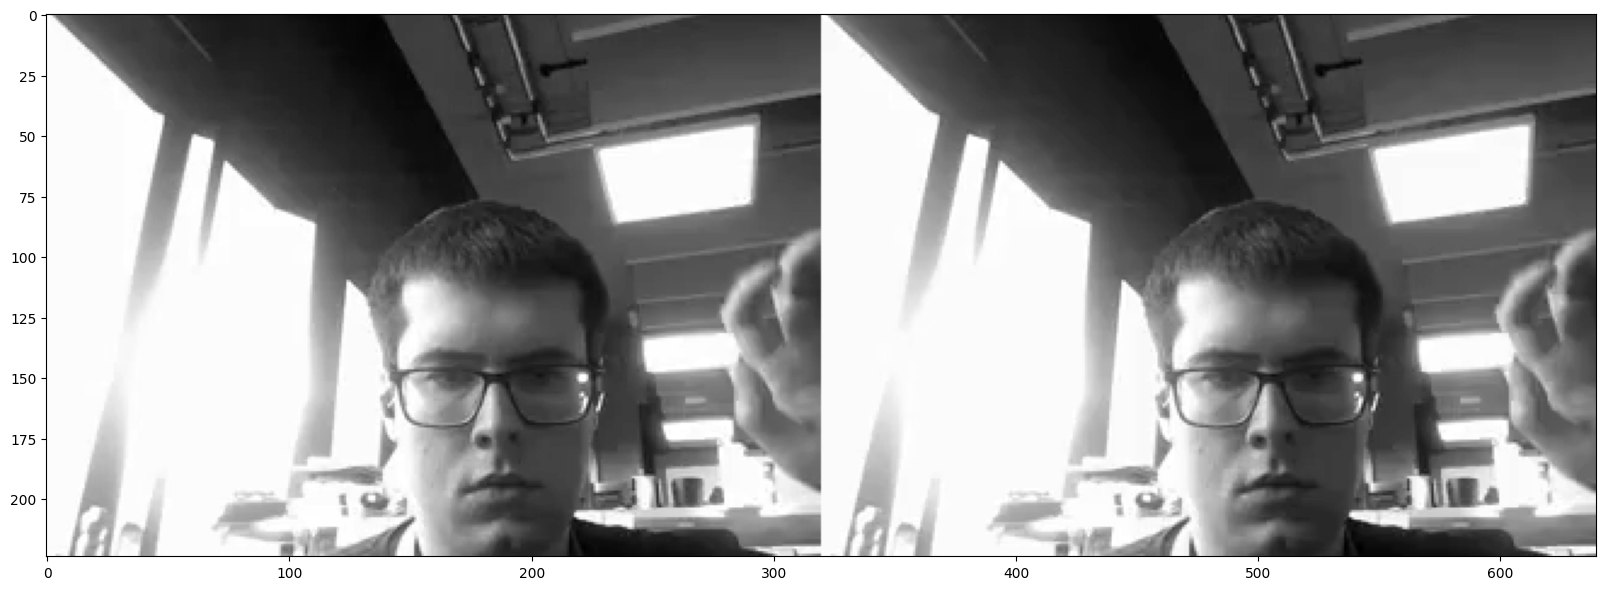

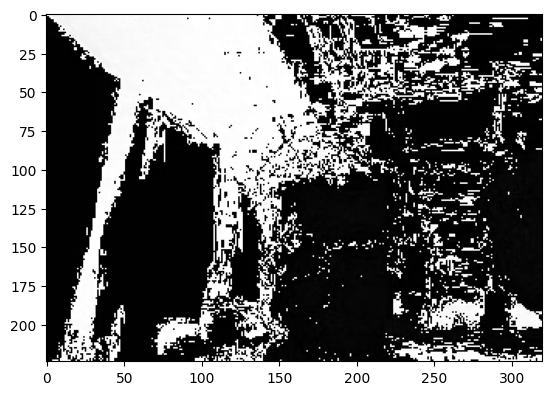

In [54]:
curr = original_frames[0]
curr = curr[8:-8,:]

up = upsampled_frames[0]

plt.figure(figsize=(20,20))
plt.imshow(np.concatenate([curr, up], axis=1), cmap="gray")
plt.savefig("comparison.png")
plt.show()

plt.imshow(np.abs(curr- up), cmap="gray")

In [70]:
tcs = []
with open("timestamps.txt") as f:
    tcs = f.readlines()

tcs = [float(line.strip()) for line in tcs]

In [109]:
from IPython.display import Video

print(len(tcs), len(upsampled_frames))

video_name = "stiched_together.mp4"
original_dt = 1 / fps_1
curr_time = 0
original_frame = None
j = 0

frame_height, frame_width = 224, 640  # from your note
fps = fps_1  # use the same FPS as original video

# Define codec and create VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # use 'mp4v' for .mp4 files
out = cv2.VideoWriter(video_name, fourcc, fps, (frame_width, frame_height))

for i in tqdm(range(len(tcs))):
    if curr_time <= 1.208375 * tcs[i]:
        original_frame = original_frames[j]
        original_frame = original_frame[8:-8,:]
        j += 1
        curr_time += original_dt

    upsampled_frame = upsampled_frames[i]

    frame_stiched_together = np.concatenate([original_frame, upsampled_frame], axis=1)
    frame_stiched_together = cv2.cvtColor(frame_stiched_together, cv2.COLOR_GRAY2BGR)

    out.write(frame_stiched_together.astype(np.uint8))  # write frame

out.release()

# In a Jupyter environment, you can display it likehis:
from IPython.display import HTML, Video

# Option A: using IPython.display.Video
display(Video(filename=video_name, embed=True,
              width=frame_width, height=frame_height))

3869 3869


  0%|          | 0/3869 [00:00<?, ?it/s]